# 009 卷积网络：题目要求

**需要完成：** 实现卷积/最大池化前后向与组合层；比较快速实现；检查三层卷积网损失和梯度；完成 100 样本过拟合与完整训练划分的一轮训练；显示卷积核；实现空间 BN。

**实验范围与验收：** 一轮三层卷积训练的训练准确率应超过 40%；数值检查需区分绝对误差与接近零梯度的相对误差。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：卷积与池化

同一个卷积核在不同位置共享。每个输出只看一个局部窗口，池化则保留窗口中的最大响应。

![卷积与池化的数据流](../assets/model_flow/009_ConvolutionalNetworks.svg)

**从定义推到实现。**

$$
Y_{nfij}=b_f+\sum_{cuv}W_{fcuv}X^{pad}_{nc,is+u,js+v}
$$

输出高度为 1+⌊(H+2p−HH)/s⌋。每个窗口对核梯度贡献输入窗口×上游梯度，对输入梯度贡献核×上游梯度。多个窗口重叠处必须累加；最大池化只把梯度送回被选中的位置。

**库在这里解决什么问题？** NumPy 朴素循环用于验证定义；快速实现把窗口排列成矩阵再做乘法，Cython 扩展将重叠的列梯度累加回像素。

**代入具体数值看公式。** 5×5 输入、3×3 核、步幅 1、补边 1 时输出仍为 5×5。中心像素属于多个窗口，反向时这些窗口的贡献要相加；只写入最后一个窗口会漏梯度。

## 从问题推到实现：为什么卷积反向需要累加

**第 1 步。** 输出位置 (i,j) 在补边后输入的起点是 (i·s,j·s)。窗口大小 HH×WW，跨越全部 C 个通道。输出宽高按 1+⌊(H+2p−HH)/s⌋ 和对应宽度式计算。

**第 2 步。** 设该位置的上游梯度为 g。一次乘积 w·x 对 w 的导数是 x，对 x 的导数是 w；因此 dW 加上 g×窗口，dX 的相应位置加上 g×核。共享核要在所有图片和位置上求和。

**第 3 步。** 快速版本把每个窗口变成一列：核矩阵 (F,C·HH·WW) 乘列矩阵 (C·HH·WW,N·Hout·Wout)。反向得到的列梯度再通过 col2im 回填；窗口重叠的位置不能覆盖。

### 关键参数逐项读

- num_filters：输出通道数 F。
- filter_size：卷积核的空间边长，不是通道数。
- stride：相邻窗口起点间隔。
- pad：四周补零宽度。
- pool_height、pool_width：最大池化窗口的高和宽。
- hidden_dim：池化展平后连接的隐藏层宽度。

### 库的整体职责与本题用法

| 库或项目包 | 整体职责 | 本题中的调用和目的 |
|---|---|---|
| `__future__` | 声明 Python 语言兼容语义，属于解释器支持的特殊导入。 | 保留代码所声明的 Python 语言语义，本身不执行数据变换。 |
| `cs231n` | 当前作业自己的本地 Python 包，封装教学数据、手写算子、模型与训练循环。 | `get_CIFAR10_data` 按本题划分读取 CIFAR-10 并预处理，返回特征和标签；`eval_numerical_gradient_array` 逐坐标扰动输入，把输出差与上游梯度相乘后求和，以检查链式法则；`eval_numerical_gradient` 通过中心差分估计标量目标对参数的导数；`Solver` 把模型、数据划分、更新规则和训练预算组合成训练器 |
| `matplotlib` | Matplotlib 是绘图库，负责把数值映射成坐标、曲线、像素和颜色。 | `plt.show` 将当前图提交给 notebook 显示；`plt.imshow` 按像素或色图显示数组，读取输出而不更新模型；`plt.plot` 把记录量按其顺序连成曲线，观察变化趋势；`plt.gcf().set_size_inches` 设置图的物理尺寸，只影响显示 |
| `numpy` | NumPy 是多维数组与数值计算库，提供广播、向量化、线性代数和随机采样。 | `np.random.seed` 设定 NumPy 的随机序列起点，便于重复同一初始化或梯度检查；`np.max` 沿指定轴得到最大数值，与 argmax 返回的位置索引区别开；`np.abs` 计算绝对值，使差异不因正负号相互抵消；`np.maximum` 逐位置取较大值，用于 ReLU 或 hinge 的截断 |
| `os` | Python 标准库的操作系统接口，管理路径、环境变量和文件操作。 | 提供运行环境接口；若当前单元只有 import，则仅注册模块。 |
| `pathlib` | Python 标准库的路径对象，用来表达目录关系和文件读写。 | 从当前作业目录定位项目根目录与结果文件。 |
| `random` | Python 标准库的伪随机数模块，与 NumPy 和 PyTorch 的随机状态分开。 | 固定 Python 的随机起点，或在图像优化中抽取平移量。 |
| `study_runtime` | 本项目的数据路径与实验记录辅助模块。 | `save_experiment` 保存已完成计算的模型与指标，避免把原始数据复制进检查点 |
| `sys` | Python 标准库的解释器接口，可配置模块搜索路径。 | 把项目根目录加入模块搜索路径，使本作业找到共享辅助代码。 |
| `threadpoolctl` | 控制底层数值库线程池的工具，可使计时实验的线程设置一致。 | `threadpool_limits` 限制底层数值线程，避免小矩阵计算受过多线程调度影响 |
| `time` | Python 标准库的计时模块，用于测量持续时间和记录时刻。 | 用于本题显式导入的接口。 |

# 卷积网络
到目前为止，我们已经使用深度全连接网络，使用它们来探索不同的优化策略和网络架构。全连接网络是一个很好的实验平台，因为它们的计算效率非常高，但实际上，所有最先进的结果都使用了卷积网络。
首先，您将实现几个在卷积网络中使用的层类型。然后，您将使用这些层在CIFAR-10数据集上训练卷积网络。

**本段解析**

**工作机制与执行链。** 这个单元初始化实验上下文。将当前作业的父目录加入 sys.path 后，Python 可以找到共享的 study_runtime；当前目录仍提供该 assignment 自己的 cs231n 包。NumPy 和标准库 random 分别设种子，threadpool_limits 设置 BLAS 的线程上限。下一单元才真正读取数据或实例化模型。

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `threadpool_limits` | `limits=4` | 底层 BLAS 线程数上限，影响并行调度和计时。 |
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备卷积算子**

**工作机制与执行链。** 先验证卷积和池化的局部算子，再验证组合层与模型；这样数值异常时能从最小出错环节查起。

导入卷积网络、基础层、数值梯度和 Solver。本题先检查单个卷积/池化算子，再检查组合层与整网，最后才进行 CIFAR-10 训练。

此处定义 `rel_error(x, y)`。函数体在调用时执行。

本块实际导入：`__future__.print_function`、`numpy`、`matplotlib.pyplot`、`cs231n.classifiers.cnn.*`、`cs231n.data_utils.get_CIFAR10_data`、`cs231n.gradient_check.eval_numerical_gradient_array`、`cs231n.gradient_check.eval_numerical_gradient`、`cs231n.layers.*`、`cs231n.fast_layers.*`、`cs231n.solver.Solver`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`rel_error` → 第 4 块。

In [2]:
from __future__ import print_function
import numpy as np
import matplotlib.pyplot as plt
from cs231n.classifiers.cnn import *
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient_array, eval_numerical_gradient
from cs231n.layers import *
from cs231n.fast_layers import *
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) 
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# IPython 加载 autoreload 扩展，使内核能够重新导入改动过的 Python 模块。
%load_ext autoreload
# 模式 2 在执行新单元前检查可重载模块。它不重新训练模型，也不清空已有变量。
%autoreload 2

def rel_error(x, y):
  """逐元素计算 |x−y| / max(1e−8, |x|+|y|)，返回其中最大值。分母很小时还应查看绝对误差。"""
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

**第 3 块｜读取 NCHW 图像**

**工作机制与执行链。** 读取 NCHW 数据后，第二轴是通道，不是图像高度。把 HWC 直接传给卷积会使核的输入通道数错误。

读取中心化后的 NCHW CIFAR-10 数据。卷积的通道维必须位于第二维，与作业一直接展示的 HWC 图像不同。

本块产出的变量接着用于：`data` → 第 15 块。

**进入底层实现。**

- [`get_CIFAR10_data`](cs231n/data_utils.py#L56)：依次完成划分、用训练均值中心化、HWC→CHW 转换，再把六个数组装入字典。只有训练均值可用于预处理验证与测试数据。


**形状怎么核对。**

本次已执行单元打印：`X_train:  (49000, 3, 32, 32)`；`y_train:  (49000,)`；`X_val:  (1000, 3, 32, 32)`；`y_val:  (1000,)`；`X_test:  (1000, 3, 32, 32)`；`y_test:  (1000,)`。

**这里没有显式传入、但实际生效的默认参数。**

- `get_CIFAR10_data(..., num_training=49000)`：用于参数拟合的训练行数。
- `get_CIFAR10_data(..., num_validation=1000)`：独立验证划分的行数。
- `get_CIFAR10_data(..., num_test=1000)`：测试阶段评估的样本数。
- `get_CIFAR10_data(..., subtract_mean=True)`：是否减去由训练数据估计的均值。

In [3]:

data = get_CIFAR10_data()
for k, v in data.items():
  print('%s: ' % k, v.shape)

X_train:  (49000, 3, 32, 32)
y_train:  (49000,)
X_val:  (1000, 3, 32, 32)
y_val:  (1000,)
X_test:  (1000, 3, 32, 32)
y_test:  (1000,)


# 卷积:简单的前向传递
卷积网络的核心是卷积运算。在文件`cs231n/layers`中。在函数`conv_forward_naive`中实现卷积层的前向传递。
在这一点上你不必太担心效率;只要用你认为最清楚的方式来写代码。
你可以通过运行以下程序来测试你的实现:

**第 4 块｜用固定核验证朴素卷积**

**工作机制与执行链。** 给定两个输入、三个核和固定 stride/pad，逐窗口计算预期输出。核的空间宽度与输入通道必须同时匹配。

用固定输入和卷积核检查带 padding、stride 的朴素卷积前向。输出空间尺寸为 1+(H+2p−HH)/s 和对应宽度；核在空间滑动时同时覆盖全部输入通道。

- `np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.linspace` | `num=3` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `conv_forward_naive` | `x=x` | (N,C,H,W) 输入图像。 |
| `conv_forward_naive` | `w=w` | (F,C,HH,WW) 卷积核，F 决定输出通道数。 |
| `conv_forward_naive` | `b=b` | (F,) 每个输出通道共享一个偏置。 |
| `conv_forward_naive` | `conv_param=conv_param` | 卷积的 stride 和 pad 配置。 |
| `rel_error` | `x=out` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=correct_out` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `np.linspace` | `num=np.prod(x_shape)` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |
| `np.linspace` | `num=np.prod(w_shape)` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |

**本段设置的变量与配置。**

- `stride=2`：相邻窗口起点间隔。
- `pad=1`：空间边界补零宽度。

**进入底层实现。**

- [`conv_forward_naive`](cs231n/layers.py#L232)：输入 x(N,C,H,W)、卷积核 w(F,C,HH,WW) 和 F 维偏置。先 padding，再按 stride 滑动窗口，逐窗口对通道和核空间求和；输出为 N×F×Hout×Wout。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(2, 3, 4, 4)`；`w` → `(3, 3, 4, 4)`。

In [4]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)

conv_param = {'stride': 2, 'pad': 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array([[[[-0.08759809, -0.10987781],
                           [-0.18387192, -0.2109216 ]],
                          [[ 0.21027089,  0.21661097],
                           [ 0.22847626,  0.23004637]],
                          [[ 0.50813986,  0.54309974],
                           [ 0.64082444,  0.67101435]]],
                         [[[-0.98053589, -1.03143541],
                           [-1.19128892, -1.24695841]],
                          [[ 0.69108355,  0.66880383],
                           [ 0.59480972,  0.56776003]],
                          [[ 2.36270298,  2.36904306],
                           [ 2.38090835,  2.38247847]]]])

print('Testing conv_forward_naive')
print('difference: ', rel_error(out, correct_out))

Testing conv_forward_naive
difference:  2.2121476417505994e-08


# Aside:通过卷积进行图像处理
我们将设置一个包含两个图像的输入，并手动设置过滤器来执行常见的图像处理操作(灰度转换和边缘检测)，这是一种既可以检查实现又可以更好地了解卷积层可以执行的操作类型的有趣方法。卷积前向传递将对每个输入图像应用这些操作。然后，我们可以将结果可视化为一个完整性检查。

**第 5 块｜把滤波器用于真实图片**

**工作机制与执行链。** 猫狗原图先缩放、裁成一致大小并转为 NCHW，再施加手工核。这里看到的边缘来自设定滤波器，而非训练学到的分类器。

读取猫狗图片、缩放并组成 NCHW 批次，用人为设定的卷积核演示灰度和边缘响应。输出展示卷积的局部线性滤波作用，这些手工核没有经过训练。

此处定义 `imshow_noax(img, normalize=True)`。函数体在调用时执行。

- `imresize(puppy, (img_size, img_size)).transpose((2, 0, 1))`：调整轴的顺序，使下一算子的通道、空间或矩阵维度对齐。

- `imread('kitten.jpg')`：将文件解码成像素数组；保持通道布局与后续处理一致。

本块实际导入：`study_runtime.imread`、`study_runtime.imresize`。各模块在本题中的职责见开头的库说明。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `conv_forward_naive` | `x=x` | (N,C,H,W) 输入图像。 |
| `conv_forward_naive` | `w=w` | (F,C,HH,WW) 卷积核，F 决定输出通道数。 |
| `conv_forward_naive` | `b=b` | (F,) 每个输出通道共享一个偏置。 |
| `conv_forward_naive` | `conv_param={'stride': 1, 'pad': 1}` | 卷积的 stride 和 pad 配置。 |
| `imshow_noax` | `normalize=False` | Gram 矩阵是否除以 C×H×W。 |

**本段设置的变量与配置。**

- `stride=1`：相邻窗口起点间隔。
- `pad=1`：空间边界补零宽度。

**进入底层实现。**

- [`conv_forward_naive`](cs231n/layers.py#L232)：输入 x(N,C,H,W)、卷积核 w(F,C,HH,WW) 和 F 维偏置。先 padding，再按 stride 滑动窗口，逐窗口对通道和核空间求和；输出为 N×F×Hout×Wout。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(2, 3, 200, 200)`；`w` → `(2, 3, 3, 3)`。

**这里没有显式传入、但实际生效的默认参数。**

- `imshow_noax(..., normalize=True)`：Gram 矩阵是否除以 C×H×W。

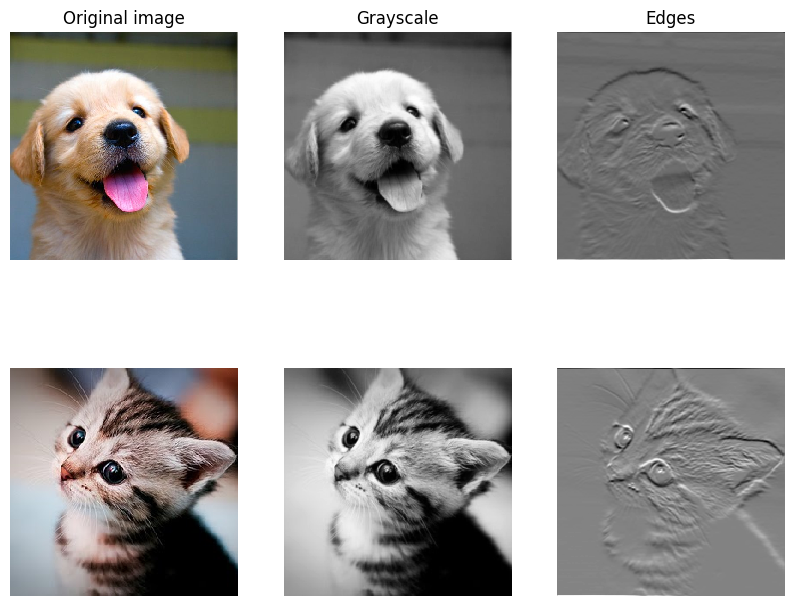

In [5]:
from study_runtime import imread, imresize

kitten, puppy = imread('kitten.jpg'), imread('puppy.jpg')
d = kitten.shape[1] - kitten.shape[0]
kitten_cropped = kitten[:, d//2:-d//2, :]

img_size = 200   
x = np.zeros((2, 3, img_size, img_size))
x[0, :, :, :] = imresize(puppy, (img_size, img_size)).transpose((2, 0, 1))
x[1, :, :, :] = imresize(kitten_cropped, (img_size, img_size)).transpose((2, 0, 1))

w = np.zeros((2, 3, 3, 3))

w[0, 0, :, :] = [[0, 0, 0], [0, 0.3, 0], [0, 0, 0]]
w[0, 1, :, :] = [[0, 0, 0], [0, 0.6, 0], [0, 0, 0]]
w[0, 2, :, :] = [[0, 0, 0], [0, 0.1, 0], [0, 0, 0]]

w[1, 2, :, :] = [[1, 2, 1], [0, 0, 0], [-1, -2, -1]]

b = np.array([0, 128])

out, _ = conv_forward_naive(x, w, b, {'stride': 1, 'pad': 1})

def imshow_noax(img, normalize=True):
    """显示输入图像并关闭坐标轴。它改变图的呈现方式，不修改参与计算的像素。"""
    if normalize:
        img_max, img_min = np.max(img), np.min(img)
        img = 255.0 * (img - img_min) / (img_max - img_min)
    plt.imshow(img.astype('uint8'))
    plt.gca().axis('off')

plt.subplot(2, 3, 1)
imshow_noax(puppy, normalize=False)
plt.title('Original image')
plt.subplot(2, 3, 2)
imshow_noax(out[0, 0])
plt.title('Grayscale')
plt.subplot(2, 3, 3)
imshow_noax(out[0, 1])
plt.title('Edges')
plt.subplot(2, 3, 4)
imshow_noax(kitten_cropped, normalize=False)
plt.subplot(2, 3, 5)
imshow_noax(out[1, 0])
plt.subplot(2, 3, 6)
imshow_noax(out[1, 1])
plt.show()

# 卷积:简单的后向传递
在文件`cs231n/layers.py`中的函数`conv_backward_naive`中实现卷积操作的向后传递。同样，你不需要太担心计算效率。
完成后，运行以下命令，用数值梯度检查检查后向遍历。

**第 6 块｜检查卷积的三个梯度**

**工作机制与执行链。** 固定随机 x、w、b 与 dout，分别对三个输入做差分。重叠窗口在 dx 上需要加法累积，在 dw 上还要跨图片求和。

随机生成小输入、卷积核和初始版本梯度，分别检查 dx、dw、db。重叠窗口对同一输入像素的贡献需要累加，padding 部分在反向结束后裁去。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `eval_numerical_gradient_array` | `x=x` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=w` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=b` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `conv_forward_naive` | `x=x` | (N,C,H,W) 输入图像。 |
| `conv_forward_naive` | `w=w` | (F,C,HH,WW) 卷积核，F 决定输出通道数。 |
| `conv_forward_naive` | `b=b` | (F,) 每个输出通道共享一个偏置。 |
| `conv_forward_naive` | `conv_param=conv_param` | 卷积的 stride 和 pad 配置。 |
| `conv_backward_naive` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `conv_backward_naive` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `rel_error` | `x=dx` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx_num` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dw` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dw_num` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=db_num` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `stride=1`：相邻窗口起点间隔。
- `pad=1`：空间边界补零宽度。

**进入底层实现。**

- [`eval_numerical_gradient_array`](cs231n/gradient_check.py#L41)：当 f 返回数组时，用初始版本 df 加权输出差分，得到链式法则对应的标量方向导数。每次扰动后恢复 x，返回与 x 同形状的数值梯度。
- [`conv_forward_naive`](cs231n/layers.py#L232)：输入 x(N,C,H,W)、卷积核 w(F,C,HH,WW) 和 F 维偏置。先 padding，再按 stride 滑动窗口，逐窗口对通道和核空间求和；输出为 N×F×Hout×Wout。
- [`conv_backward_naive`](cs231n/layers.py#L272)：依据前向窗口位置把 dout 分别累加到 dx、dw 和 db。窗口重叠时必须使用加法累积；结束后去掉输入梯度的 padding，恢复原输入尺寸。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(4, 3, 5, 5)`；`w` → `(2, 3, 3, 3)`；`b` → `(2,)`；`dout` → `(4, 2, 5, 5)`。

**这里没有显式传入、但实际生效的默认参数。**

- `eval_numerical_gradient_array(..., h=1e-05)`：中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。

In [6]:
np.random.seed(231)
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2,)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {'stride': 1, 'pad': 1}

dx_num = eval_numerical_gradient_array(lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout)

out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)

print('Testing conv_backward_naive function')
print('dx error: ', rel_error(dx, dx_num))
print('dw error: ', rel_error(dw, dw_num))
print('db error: ', rel_error(db, db_num))

Testing conv_backward_naive function
dx error:  1.159803161159293e-08
dw error:  2.247109434939654e-10
db error:  3.37264006649648e-11


# 最大池化:简单的前向
在文件`cs231n/layers.py`中的函数`max_pool_forward_naive`中实现max-pooling操作的前向传递。同样，不要太担心计算效率。
检查你的实现运行以下:

**第 7 块｜核对池化窗口最大值**

**工作机制与执行链。** 对 2×2 窗口取最大值，通道轴保持独立。固定数列使每个输出都能回到对应窗口手算核对。

对固定输入执行 2×2 最大池化并与预置结果比较。池化沿每个通道独立进行，输出每个窗口的最大值，不学习参数。

- `np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `max_pool_forward_naive` | `x=x` | (N,C,H,W) 输入，各通道独立池化。 |
| `max_pool_forward_naive` | `pool_param=pool_param` | 池化窗口宽高与步幅。 |
| `rel_error` | `x=out` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=correct_out` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `np.linspace` | `num=np.prod(x_shape)` | 在 start 与 stop 之间生成的点数，随后 reshape 所需元素数必须与它一致。 |

**本段设置的变量与配置。**

- `pool_width=2`：池化窗口宽度。
- `pool_height=2`：池化窗口高度。
- `stride=2`：相邻窗口起点间隔。

**进入底层实现。**

- [`max_pool_forward_naive`](cs231n/layers.py#L316)：按每个样本和通道遍历空间窗口，输出窗口最大值。池化不混合通道，也没有权重；cache 保留输入和窗口设置。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(2, 3, 4, 4)`。

In [7]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {'pool_width': 2, 'pool_height': 2, 'stride': 2}

out, _ = max_pool_forward_naive(x, pool_param)

correct_out = np.array([[[[-0.26315789, -0.24842105],
                          [-0.20421053, -0.18947368]],
                         [[-0.14526316, -0.13052632],
                          [-0.08631579, -0.07157895]],
                         [[-0.02736842, -0.01263158],
                          [ 0.03157895,  0.04631579]]],
                        [[[ 0.09052632,  0.10526316],
                          [ 0.14947368,  0.16421053]],
                         [[ 0.20842105,  0.22315789],
                          [ 0.26736842,  0.28210526]],
                         [[ 0.32631579,  0.34105263],
                          [ 0.38526316,  0.4       ]]]])

print('Testing max_pool_forward_naive function:')
print('difference: ', rel_error(out, correct_out))

Testing max_pool_forward_naive function:
difference:  4.1666665157267834e-08


# 最大池化:简单后向传递
在文件`cs231n/layers.py`中的函数`max_pool_backward_naive`中实现最大池操作的向后传递。你不需要担心计算效率。
检查你的实现与数值梯度检查运行以下:

**第 8 块｜检查池化反向**

**工作机制与执行链。** 将上游梯度只送回各窗口的最大位置。随机连续输入减少平票歧义，重叠窗口的梯度仍需相加。

检查最大池化反向：初始版本梯度传到对应窗口的最大元素位置。随机输入通常避免多个最大值相同的情况；重叠窗口存在时同一输入位置需累加来自多个窗口的梯度。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `eval_numerical_gradient_array` | `x=x` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `max_pool_forward_naive` | `x=x` | (N,C,H,W) 输入，各通道独立池化。 |
| `max_pool_forward_naive` | `pool_param=pool_param` | 池化窗口宽高与步幅。 |
| `max_pool_backward_naive` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `max_pool_backward_naive` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `rel_error` | `x=dx` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx_num` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `pool_height=2`：池化窗口高度。
- `pool_width=2`：池化窗口宽度。
- `stride=2`：相邻窗口起点间隔。
**本实现的边界。** 数学推导要求重叠窗口的梯度相加；当前朴素池化代码在切片上使用赋值。用 3×3 输入、中心唯一最大、2×2 窗口和步幅 1 测试，四个窗口都选中中心。上游全为一时理论中心梯度是 4，当前实现实际返回 1。课程的非重叠窗口不触发这一问题。不能从本题检查通过推断它支持任意步幅。

**进入底层实现。**

- [`eval_numerical_gradient_array`](cs231n/gradient_check.py#L41)：当 f 返回数组时，用初始版本 df 加权输出差分，得到链式法则对应的标量方向导数。每次扰动后恢复 x，返回与 x 同形状的数值梯度。
- [`max_pool_forward_naive`](cs231n/layers.py#L316)：按每个样本和通道遍历空间窗口，输出窗口最大值。池化不混合通道，也没有权重；cache 保留输入和窗口设置。
- [`max_pool_backward_naive`](cs231n/layers.py#L345)：根据缓存找到窗口最大值的位置，将对应输出梯度回传到输入；当前切片使用赋值，作业采用的不重叠窗口可这样写；重叠窗口在数学上需要累加，而当前函数不支持这个推广。并列最大值按掩码同时接收上游值。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(3, 2, 8, 8)`；`dout` → `(3, 2, 4, 4)`。

**这里没有显式传入、但实际生效的默认参数。**

- `eval_numerical_gradient_array(..., h=1e-05)`：中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。

In [8]:
np.random.seed(231)
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

dx_num = eval_numerical_gradient_array(lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout)

out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)

print('Testing max_pool_backward_naive function:')
print('dx error: ', rel_error(dx, dx_num))

Testing max_pool_backward_naive function:
dx error:  3.27562514223145e-12


# 快速层
快速实现卷积和池化层具有挑战性。为了避免麻烦，我们在文件`cs231n/fast_layers.py`中为卷积和池化层提供了向前和向后传递的快速实现。
快速卷积的实现依赖于一个Cython扩展;要编译它，你需要运行以下`cs231n `目录:

```bash
python setup.py build_ext --inplace
```
卷积和池化层的快速版本的API与上面实现的原始版本完全相同:前向传递接收数据、权重和参数，并产生输出和缓存对象;后向传递接收初始版本导数和缓存对象，并产生与数据和权重相关的梯度。

**注:** 池的快速实现只有在池区域不重叠和平铺输入时才会优化执行。如果不满足这些条件，那么快速池实现不会比简单实现快很多。

你可以比较这些层的性能简单和快速版本运行以下:

**第 9 块｜比较快速与朴素卷积**

**工作机制与执行链。** 朴素版本与快速版本读取相同输入；对齐输出后，再比较 dx、dw、db。快速反向的关键是把列梯度累加回图像。

对相同输入比较 Cython 加速卷积与朴素卷积的前向、反向和耗时。加速实现将窗口重排为列，用矩阵乘法计算卷积，反向再把列梯度累加回图像；需先证明数值一致。

本块实际导入：`cs231n.fast_layers.conv_forward_fast`、`cs231n.fast_layers.conv_backward_fast`、`time.perf_counter`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `conv_forward_naive` | `x=x` | (N,C,H,W) 输入图像。 |
| `conv_forward_naive` | `w=w` | (F,C,HH,WW) 卷积核，F 决定输出通道数。 |
| `conv_forward_naive` | `b=b` | (F,) 每个输出通道共享一个偏置。 |
| `conv_forward_naive` | `conv_param=conv_param` | 卷积的 stride 和 pad 配置。 |
| `conv_backward_naive` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `conv_backward_naive` | `cache=cache_naive` | 前向留下的中间状态，反向按对应顺序读取。 |
| `rel_error` | `x=out_naive` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=out_fast` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dx_naive` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx_fast` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dw_naive` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dw_fast` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db_naive` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=db_fast` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `stride=2`：相邻窗口起点间隔。
- `pad=1`：空间边界补零宽度。

**进入底层实现。**

- [`conv_forward_naive`](cs231n/layers.py#L232)：输入 x(N,C,H,W)、卷积核 w(F,C,HH,WW) 和 F 维偏置。先 padding，再按 stride 滑动窗口，逐窗口对通道和核空间求和；输出为 N×F×Hout×Wout。
- [`conv_backward_naive`](cs231n/layers.py#L272)：依据前向窗口位置把 dout 分别累加到 dx、dw 和 db。窗口重叠时必须使用加法累积；结束后去掉输入梯度的 padding，恢复原输入尺寸。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(100, 3, 31, 31)`；`w` → `(25, 3, 3, 3)`；`b` → `(25,)`；`dout` → `(100, 25, 16, 16)`。

In [9]:
from cs231n.fast_layers import conv_forward_fast, conv_backward_fast
from time import perf_counter as time
np.random.seed(231)
x = np.random.randn(100, 3, 31, 31)
w = np.random.randn(25, 3, 3, 3)
b = np.random.randn(25,)
dout = np.random.randn(100, 25, 16, 16)
conv_param = {'stride': 2, 'pad': 1}

t0 = time()
out_naive, cache_naive = conv_forward_naive(x, w, b, conv_param)
t1 = time()
out_fast, cache_fast = conv_forward_fast(x, w, b, conv_param)
t2 = time()

print('Testing conv_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('Difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive, dw_naive, db_naive = conv_backward_naive(dout, cache_naive)
t1 = time()
dx_fast, dw_fast, db_fast = conv_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting conv_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))
print('dw difference: ', rel_error(dw_naive, dw_fast))
print('db difference: ', rel_error(db_naive, db_fast))

Testing conv_forward_fast:
Naive: 0.074602s
Fast: 0.003667s
Speedup: 20.344123x
Difference:  4.926407851494105e-11



Testing conv_backward_fast:
Naive: 0.239628s
Fast: 0.004061s
Speedup: 59.008520x
dx difference:  1.006330206620509e-11
dw difference:  1.3447168126646626e-13
db difference:  0.0


**第 10 块｜比较快速与朴素池化**

**工作机制与执行链。** 比较池化的两条实现时要保持窗口与步幅相同。reshape 快速路径需要窗口能整齐分块，否则采用展开路径。

比较快速最大池化与朴素实现，包括输出和输入梯度。可整齐划分的窗口采用 reshape 路径，其他情况使用窗口展开；计时只反映当前输入规模。

本块实际导入：`cs231n.fast_layers.max_pool_forward_fast`、`cs231n.fast_layers.max_pool_backward_fast`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `max_pool_forward_naive` | `x=x` | (N,C,H,W) 输入，各通道独立池化。 |
| `max_pool_forward_naive` | `pool_param=pool_param` | 池化窗口宽高与步幅。 |
| `max_pool_forward_fast` | `x=x` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `max_pool_forward_fast` | `pool_param=pool_param` | 池化窗口宽高与步幅。 |
| `max_pool_backward_naive` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `max_pool_backward_naive` | `cache=cache_naive` | 前向留下的中间状态，反向按对应顺序读取。 |
| `max_pool_backward_fast` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `max_pool_backward_fast` | `cache=cache_fast` | 前向留下的中间状态，反向按对应顺序读取。 |
| `rel_error` | `x=out_naive` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=out_fast` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dx_naive` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx_fast` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `pool_height=2`：池化窗口高度。
- `pool_width=2`：池化窗口宽度。
- `stride=2`：相邻窗口起点间隔。

**进入底层实现。**

- [`max_pool_forward_naive`](cs231n/layers.py#L316)：按每个样本和通道遍历空间窗口，输出窗口最大值。池化不混合通道，也没有权重；cache 保留输入和窗口设置。
- [`max_pool_forward_fast`](cs231n/fast_layers.py#L134)：按池化窗口与步幅选择快速排列方式，输出局部最大值并保留方法标记和 cache。reshape 路径仅适用于可整齐划分的窗口，其他情况使用展开路径。
- [`max_pool_backward_naive`](cs231n/layers.py#L345)：根据缓存找到窗口最大值的位置，将对应输出梯度回传到输入；当前切片使用赋值，作业采用的不重叠窗口可这样写；重叠窗口在数学上需要累加，而当前函数不支持这个推广。并列最大值按掩码同时接收上游值。
- [`max_pool_backward_fast`](cs231n/fast_layers.py#L159)：按前向的方法标记恢复窗口布局，把初始版本梯度送回最大值位置并还原输入形状。并列最大值分配采用此快速实现约定，随机无并列测试应与朴素实现一致。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(100, 3, 32, 32)`；`dout` → `(100, 3, 16, 16)`。

In [10]:
from cs231n.fast_layers import max_pool_forward_fast, max_pool_backward_fast
np.random.seed(231)
x = np.random.randn(100, 3, 32, 32)
dout = np.random.randn(100, 3, 16, 16)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

t0 = time()
out_naive, cache_naive = max_pool_forward_naive(x, pool_param)
t1 = time()
out_fast, cache_fast = max_pool_forward_fast(x, pool_param)
t2 = time()

print('Testing pool_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive = max_pool_backward_naive(dout, cache_naive)
t1 = time()
dx_fast = max_pool_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting pool_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))

Testing pool_forward_fast:
Naive: 0.003676s
fast: 0.002264s
speedup: 1.623531x
difference:  0.0

Testing pool_backward_fast:
Naive: 0.006719s
speedup: 1.222894x
dx difference:  0.0


# 卷积的“三明治”层
前面我们介绍了“三明治”层的概念，它将多个操作组合成常用的模式。在文件`cs231n/layer_utils`中。你会发现三明治层实现了一些常用的卷积网络模式。

**第 11 块｜检查卷积、激活、池化串联**

**工作机制与执行链。** 组合层前向为 conv→ReLU→pool，反向为 pool→ReLU→conv。三个 cache 必须一一匹配各自算子。

对 conv→ReLU→pool 组合层执行梯度检查。反向按 pool→ReLU→conv 逆序展开，并使用各层独立 cache，输出对输入、卷积核和偏置的梯度。

本块实际导入：`cs231n.layer_utils.conv_relu_pool_forward`、`cs231n.layer_utils.conv_relu_pool_backward`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `conv_relu_pool_forward` | `x=x` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `conv_relu_pool_forward` | `w=w` | 本层权重。 |
| `conv_relu_pool_forward` | `b=b` | 偏置，沿样本维广播。 |
| `conv_relu_pool_forward` | `conv_param=conv_param` | 卷积的 stride 和 pad 配置。 |
| `conv_relu_pool_forward` | `pool_param=pool_param` | 池化窗口宽高与步幅。 |
| `conv_relu_pool_backward` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `conv_relu_pool_backward` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `eval_numerical_gradient_array` | `x=x` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=w` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=b` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `rel_error` | `x=dx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dw_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dw` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=db` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `stride=2`：相邻窗口起点间隔。
- `pad=1`：空间边界补零宽度。
- `pool_height=2`：池化窗口高度。
- `pool_width=2`：池化窗口宽度。

**进入底层实现。**

- [`conv_relu_pool_forward`](cs231n/layer_utils.py#L130)：按 conv → relu → pool 顺序调用基础层，将各层 cache 按相同顺序保存。输出最终激活及组合 cache；该包装不额外引入训练参数。
- [`conv_relu_pool_backward`](cs231n/layer_utils.py#L150)：读取 conv_relu_pool 前向保存的各层 cache，按计算顺序的逆序传播 dout。返回输入梯度和各参数梯度，具体形状与各基础层接口一致。
- [`eval_numerical_gradient_array`](cs231n/gradient_check.py#L41)：当 f 返回数组时，用初始版本 df 加权输出差分，得到链式法则对应的标量方向导数。每次扰动后恢复 x，返回与 x 同形状的数值梯度。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(2, 3, 16, 16)`；`w` → `(3, 3, 3, 3)`；`b` → `(3,)`；`dout` → `(2, 3, 8, 8)`。

**这里没有显式传入、但实际生效的默认参数。**

- `eval_numerical_gradient_array(..., h=1e-05)`：中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。

In [11]:
from cs231n.layer_utils import conv_relu_pool_forward, conv_relu_pool_backward
np.random.seed(231)
x = np.random.randn(2, 3, 16, 16)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

out, cache = conv_relu_pool_forward(x, w, b, conv_param, pool_param)
dx, dw, db = conv_relu_pool_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], b, dout)

print('Testing conv_relu_pool')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu_pool
dx error:  9.591132621921372e-09
dw error:  5.802455944849637e-09
db error:  3.57960501324485e-10


**第 12 块｜检查卷积与激活串联**

**工作机制与执行链。** 去掉池化后单独检查 conv→ReLU。如果前一组失败而此组通过，可优先排查池化或其缓存接口。

检查不带池化的 conv→ReLU 组合，确认缓存与梯度传播可以复用。与上一实验相比仅移除池化，不应改变卷积核梯度的基本计算规则。

本块实际导入：`cs231n.layer_utils.conv_relu_forward`、`cs231n.layer_utils.conv_relu_backward`。各模块在本题中的职责见开头的库说明。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `conv_relu_forward` | `x=x` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `conv_relu_forward` | `w=w` | 本层权重。 |
| `conv_relu_forward` | `b=b` | 偏置，沿样本维广播。 |
| `conv_relu_forward` | `conv_param=conv_param` | 卷积的 stride 和 pad 配置。 |
| `conv_relu_backward` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `conv_relu_backward` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `eval_numerical_gradient_array` | `x=x` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=w` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=b` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `rel_error` | `x=dx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=dw_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dw` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=db` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `stride=1`：相邻窗口起点间隔。
- `pad=1`：空间边界补零宽度。

**进入底层实现。**

- [`conv_relu_forward`](cs231n/layer_utils.py#L78)：按 conv → relu 顺序调用基础层，将各层 cache 按相同顺序保存。输出最终激活及组合 cache；该包装不额外引入训练参数。
- [`conv_relu_backward`](cs231n/layer_utils.py#L96)：读取 conv_relu 前向保存的各层 cache，按计算顺序的逆序传播 dout。返回输入梯度和各参数梯度，具体形状与各基础层接口一致。
- [`eval_numerical_gradient_array`](cs231n/gradient_check.py#L41)：当 f 返回数组时，用初始版本 df 加权输出差分，得到链式法则对应的标量方向导数。每次扰动后恢复 x，返回与 x 同形状的数值梯度。


**形状怎么核对。**

由构造或 reshape 的实参可直接读出：`x` → `(2, 3, 8, 8)`；`w` → `(3, 3, 3, 3)`；`b` → `(3,)`；`dout` → `(2, 3, 8, 8)`。

**这里没有显式传入、但实际生效的默认参数。**

- `eval_numerical_gradient_array(..., h=1e-05)`：中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。

In [12]:
from cs231n.layer_utils import conv_relu_forward, conv_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 8, 8)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}

out, cache = conv_relu_forward(x, w, b, conv_param)
dx, dw, db = conv_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_forward(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_forward(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_forward(x, w, b, conv_param)[0], b, dout)

print('Testing conv_relu:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu:
dx error:  1.5218619980349303e-09
dw error:  3.3715893156038223e-10
db error:  4.8422803898140394e-11


# 三层卷积网络
现在您已经实现了所有必要的层，我们可以将它们放到一个简单的卷积网络中。
打开文件`cs231n/classifiers/cnn`。完成`ThreeLayerConvNet`类的实现。运行以下单元来帮助您调试:

检查损失
在你建立一个新的网络之后，你应该做的第一件事就是检查损失。当我们使用softmax损失时，我们期望随机权重的损失(没有正则化)是关于“log(C)”的“C”类。当我们添加正则化时，这个应该会增加。

**第 13 块｜检查整网初始损失**

**工作机制与执行链。** 随机小权重下十类得分接近，损失应接近 log(10)。保持参数不变增大 reg，损失应增加权重平方惩罚。

创建三层卷积网络，在随机图像和标签上检查初始损失及正则化效应。随机小参数的交叉熵应接近 log(10)，加入 L2 正则后损失应按权重范数增加。

- `np.random.randint(10, size=N)`：从给定整数范围抽样，结果用作索引或离散标签。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.randint` | `size=N` | 采样时是输出尺寸；图像缩放时是目标尺寸。 |

**进入底层实现。**

- [`ThreeLayerConvNet`](cs231n/classifiers/cnn.py#L9)：三层卷积分类器。卷积、ReLU 和最大池化提取空间特征，随后经过仿射隐藏层与最终分类层。模型接收 NCHW 图像，返回类别得分或训练损失与梯度。
- [`model.loss`](cs231n/classifiers/cnn.py#L60)：依次调用组合层进行前向，无标签时返回 logits；有标签时计算 Softmax 和仅作用于权重的 L2 正则，逆序返回 W1/b1 到 W3/b3 的梯度。


**形状怎么核对。**

本块显式设定：`N=50` 表示该批次的样本数。

由构造或 reshape 的实参可直接读出：`X` → `(50, 3, 32, 32)`。

**这里没有显式传入、但实际生效的默认参数。**

- `ThreeLayerConvNet(..., input_dim=(3, 32, 32))`：输入的特征维或图像 (C,H,W) 形状。
- `ThreeLayerConvNet(..., num_filters=32)`：卷积输出通道数。
- `ThreeLayerConvNet(..., filter_size=7)`：卷积核的空间边长。
- `ThreeLayerConvNet(..., hidden_dim=100)`：隐藏表示的宽度。
- `ThreeLayerConvNet(..., num_classes=10)`：输出类别数，对应 logits 的类别轴宽度。
- `ThreeLayerConvNet(..., weight_scale=0.001)`：初始权重的标准差。
- `ThreeLayerConvNet(..., reg=0.0)`：权重的 L2 惩罚系数。
- `ThreeLayerConvNet(..., dtype=np.float32)`：参数数值类型，用于控制数值精度。

In [13]:
model = ThreeLayerConvNet()

N = 50
X = np.random.randn(N, 3, 32, 32)
y = np.random.randint(10, size=N)

loss, grads = model.loss(X, y)
print('Initial loss (no regularization): ', loss)

model.reg = 0.5
loss, grads = model.loss(X, y)
print('Initial loss (with regularization): ', loss)

Initial loss (no regularization): 

 2.302586071243987
Initial loss (with regularization):  2.508255638232932


## 梯度检查
在损失看起来合理之后，使用数值梯度检查来确保您的后向传递是正确的。当你使用数值梯度检查时，你应该在每一层使用少量的人工数据和少量的神经元。注意:正确的实现在1e-2之前仍然可能有相对错误。

**第 14 块｜检查整网参数梯度**

**工作机制与执行链。** 在小输入和小模型上逐元素扰动所有参数。接近零的梯度会放大相对误差，因此同时保留绝对误差与框架对照。

使用较小图像和隐藏层逐参数做整网数值梯度检查。此时同时覆盖卷积、池化、仿射和 Softmax 链条，计算比单层检查更贵，但能发现层间形状或缓存错误。

- `np.random.randint(num_classes, size=num_inputs)`：从给定整数范围抽样，结果用作索引或离散标签。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `np.random.randint` | `size=num_inputs` | 采样时是输出尺寸；图像缩放时是目标尺寸。 |
| `ThreeLayerConvNet` | `num_filters=3` | 卷积核数，也是卷积输出的通道数。 |
| `ThreeLayerConvNet` | `filter_size=3` | 卷积核的空间边长。 |
| `ThreeLayerConvNet` | `input_dim=input_dim` | 输入特征宽度；卷积构造器中用三元组表示通道、高、宽。 |
| `ThreeLayerConvNet` | `hidden_dim=7` | 隐藏层或循环状态的宽度，决定内部表示能容纳多少分量。 |
| `ThreeLayerConvNet` | `dtype=np.float64` | 数据类型；float64 用于检查微小差分，float32 常用于正式训练。 |
| `eval_numerical_gradient` | `verbose=False` | 控制是否打印进度，预算由轮数或更新次数决定。 |
| `eval_numerical_gradient` | `h=1e-06` | 中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。 |
| `eval_numerical_gradient` | `x=model.params[param_name]` | 被中心差分逐坐标扰动的数组，可以是模型权重或输入。 |
| `rel_error` | `x=param_grad_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=grads[param_name]` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `input_dim=(3, 16, 16)`：输入特征宽度；卷积构造器中用三元组表示通道、高、宽。
- `reg=0.0`：L2 正则强度；在本题权重平方和损失的系数与导数中同时出现。
- `num_classes=10`：输出类别数，对应 logits 的类别轴宽度。

**进入底层实现。**

- [`ThreeLayerConvNet`](cs231n/classifiers/cnn.py#L9)：三层卷积分类器。卷积、ReLU 和最大池化提取空间特征，随后经过仿射隐藏层与最终分类层。模型接收 NCHW 图像，返回类别得分或训练损失与梯度。
- [`model.loss`](cs231n/classifiers/cnn.py#L60)：依次调用组合层进行前向，无标签时返回 logits；有标签时计算 Softmax 和仅作用于权重的 L2 正则，逆序返回 W1/b1 到 W3/b3 的梯度。
- [`eval_numerical_gradient`](cs231n/gradient_check.py#L10)：逐坐标计算中心差分 [f(x+h)−f(x−h)]/(2h)，每次恢复被扰动元素。适用于标量输出；步长过大会跨越非光滑点，过小会产生消去误差。


**这里没有显式传入、但实际生效的默认参数。**

- `ThreeLayerConvNet(..., num_classes=10)`：输出类别数，对应 logits 的类别轴宽度。
- `ThreeLayerConvNet(..., weight_scale=0.001)`：初始权重的标准差。
- `ThreeLayerConvNet(..., reg=0.0)`：权重的 L2 惩罚系数。

In [14]:
num_inputs = 2
input_dim = (3, 16, 16)
reg = 0.0
num_classes = 10
np.random.seed(231)
X = np.random.randn(num_inputs, *input_dim)
y = np.random.randint(num_classes, size=num_inputs)

model = ThreeLayerConvNet(num_filters=3, filter_size=3,
                          input_dim=input_dim, hidden_dim=7,
                          dtype=np.float64)
loss, grads = model.loss(X, y)
for param_name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    param_grad_num = eval_numerical_gradient(f, model.params[param_name], verbose=False, h=1e-6)
    e = rel_error(param_grad_num, grads[param_name])
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W1 max relative error: 1.380104e-04

W2 max relative error: 1.822723e-02
W3 max relative error: 3.064049e-04
b1 max relative error: 3.477652e-05
b2 max relative error: 2.516375e-03
b3 max relative error: 7.945660e-10


## 小数据过拟合
一个不错的技巧是使用一些训练样本来训练您的模型。您应该能够过度适合小的数据集，这将导致非常高的训练精度和相对较低的验证精度。

**第 15 块｜在 100 张图上拟合**

**工作机制与执行链。** 用 100 张训练图训练 15 轮，目的在于确认整网能记忆小集合。这个训练分母与正式训练不同。

在 100 张训练图上训练三层卷积网络 15 轮，检查模型是否有能力过拟合。该步骤有意使用小数据，训练准确率高而验证低是合理现象，不应当作正式泛化结果。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`solver` → 第 16 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `ThreeLayerConvNet` | `weight_scale=0.01` | 权重初始化的标准差，影响前向激活和反向梯度的初始量级。 |
| `Solver` | `num_epochs=15` | 完整训练轮数；不是每一轮的 batch 数。 |
| `Solver` | `batch_size=50` | 单次前向和更新使用的样本数；与训练集大小一起决定每轮的更新次数。 |
| `Solver` | `update_rule='adam'` | Solver 选择的参数更新函数，如 SGD、RMSProp 或 Adam。 |
| `Solver` | `optim_config={'learning_rate': 0.0001}` | 优化器的配置字典，学习率和跨步状态按参数分别管理。 |
| `Solver` | `verbose=True` | 控制是否打印进度，预算由轮数或更新次数决定。 |
| `Solver` | `print_every=1` | 相邻两次训练进度打印之间的更新次数。 |
| `Solver` | `model=model` | 当前待训练或评估的模型对象。 |
| `Solver` | `data=small_data` | 包含训练与验证数据的字典。 |

**本段设置的变量与配置。**

- `learning_rate=0.0001`：每次更新沿梯度方向移动的步长，过大会使损失上升或发散。

**进入底层实现。**

- [`ThreeLayerConvNet`](cs231n/classifiers/cnn.py#L9)：三层卷积分类器。卷积、ReLU 和最大池化提取空间特征，随后经过仿射隐藏层与最终分类层。模型接收 NCHW 图像，返回类别得分或训练损失与梯度。
- [`Solver`](cs231n/solver.py#L15)：负责分类训练的外层循环。每次从训练集抽一批，调用 model.loss 获得损失和梯度，再用指定更新规则调整参数。每个参数的优化器状态独立保存，验证集用于选择最佳权重。
- [`solver.train`](cs231n/solver.py#L152)：执行指定轮数的采样更新，周期性评估训练/验证准确率，记录曲线并保留验证最优参数；最终把最佳参数恢复到模型。


**这里没有显式传入、但实际生效的默认参数。**

- `ThreeLayerConvNet(..., input_dim=(3, 32, 32))`：输入的特征维或图像 (C,H,W) 形状。
- `ThreeLayerConvNet(..., num_filters=32)`：卷积输出通道数。
- `ThreeLayerConvNet(..., filter_size=7)`：卷积核的空间边长。
- `ThreeLayerConvNet(..., hidden_dim=100)`：隐藏表示的宽度。
- `ThreeLayerConvNet(..., num_classes=10)`：输出类别数，对应 logits 的类别轴宽度。
- `ThreeLayerConvNet(..., reg=0.0)`：权重的 L2 惩罚系数。
- `ThreeLayerConvNet(..., dtype=np.float32)`：参数数值类型，用于控制数值精度。
- `Solver(..., lr_decay=1.0)`：每轮结束后乘到学习率上的因子。
- `Solver(..., num_train_samples=1000)`：检查训练准确率时使用的抽样数，不是训练子集大小。
- `Solver(..., num_val_samples=None)`：检查验证准确率时使用的抽样数，None 使用完整指定划分。
- `Solver(..., checkpoint_name=None)`：检查点文件的前缀，None 表示该 Solver 不写此类文件。

In [15]:
np.random.seed(231)

num_train = 100
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

model = ThreeLayerConvNet(weight_scale=1e-2)

solver = Solver(model, small_data,
                num_epochs=15, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-4,
                },
                verbose=True, print_every=1)
solver.train()

(Iteration 1 / 30) loss: 2.414060


(Epoch 0 / 15) train acc: 0.160000; val_acc: 0.093000
(Iteration 2 / 30) loss: 2.290796


(Epoch 1 / 15) train acc: 0.210000; val_acc: 0.115000
(Iteration 3 / 30) loss: 2.089441


(Iteration 4 / 30) loss: 2.091442


(Epoch 2 / 15) train acc: 0.270000; val_acc: 0.127000
(Iteration 5 / 30) loss: 1.914290


(Iteration 6 / 30) loss: 2.002273


... (21 outputs left out)

(Iteration 28 / 30) loss: 0.618615


(Epoch 14 / 15) train acc: 0.950000; val_acc: 0.194000
(Iteration 29 / 30) loss: 0.540485


(Iteration 30 / 30) loss: 0.625012


(Epoch 15 / 15) train acc: 0.940000; val_acc: 0.203000


绘制损失、训练精度和验证精度应该显示清楚的过拟合:

**第 16 块｜查看小样本曲线**

**工作机制与执行链。** 从小样本 Solver 读取损失和准确率轨迹，观察拟合是否形成，同时区分训练与验证的明显差距。

绘制小样本实验的损失、训练与验证准确率，检查过拟合趋势。若训练准确率也上不去，应先排查实现或优化配置，再进入完整训练。

前序输入：`solver` 来自第 15 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `plt.legend` | `loc='upper left'` | Matplotlib 图例的位置。 |

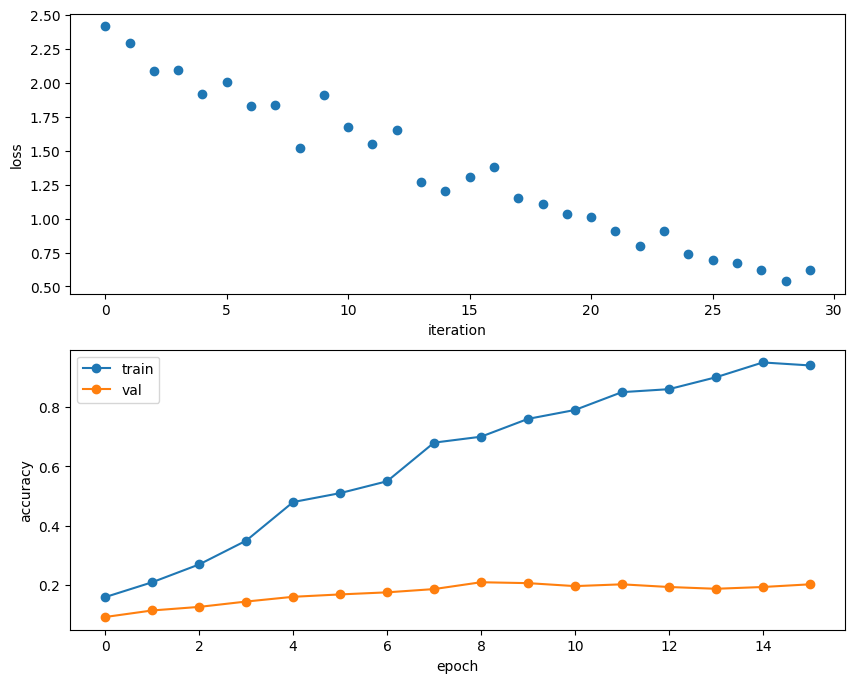

In [16]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, 'o')
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(['train', 'val'], loc='upper left')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

## 训练网络
通过对三层卷积网络进行1个epoch的训练，训练集的准确率应达到40%以上:

**第 17 块｜完成一轮正式训练**

**工作机制与执行链。** 在完整训练划分运行一轮。batch_size 决定每轮更新数，Solver 负责训练及验证，最后恢复验证最佳权重。

在完整课程训练划分上，以隐藏维度 500、权重尺度 0.001 和正则强度 0.001 训练一个完整 epoch。保留原题预算，检查训练准确率超过 40% 的目标，并保存模型与验证轨迹。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`model` → 第 18 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `ThreeLayerConvNet` | `weight_scale=0.001` | 权重初始化的标准差，影响前向激活和反向梯度的初始量级。 |
| `ThreeLayerConvNet` | `hidden_dim=500` | 隐藏层或循环状态的宽度，决定内部表示能容纳多少分量。 |
| `ThreeLayerConvNet` | `reg=0.001` | L2 正则强度；在本题权重平方和损失的系数与导数中同时出现。 |
| `Solver` | `num_epochs=1` | 完整训练轮数；不是每一轮的 batch 数。 |
| `Solver` | `batch_size=50` | 单次前向和更新使用的样本数；与训练集大小一起决定每轮的更新次数。 |
| `Solver` | `update_rule='adam'` | Solver 选择的参数更新函数，如 SGD、RMSProp 或 Adam。 |
| `Solver` | `optim_config={'learning_rate': 0.0001}` | 优化器的配置字典，学习率和跨步状态按参数分别管理。 |
| `Solver` | `verbose=True` | 控制是否打印进度，预算由轮数或更新次数决定。 |
| `Solver` | `print_every=20` | 相邻两次训练进度打印之间的更新次数。 |
| `Solver` | `model=model` | 当前待训练或评估的模型对象。 |
| `Solver` | `data=data` | 包含训练与验证数据的字典。 |

**本段设置的变量与配置。**

- `learning_rate=0.0001`：每次更新沿梯度方向移动的步长，过大会使损失上升或发散。

**进入底层实现。**

- [`ThreeLayerConvNet`](cs231n/classifiers/cnn.py#L9)：三层卷积分类器。卷积、ReLU 和最大池化提取空间特征，随后经过仿射隐藏层与最终分类层。模型接收 NCHW 图像，返回类别得分或训练损失与梯度。
- [`Solver`](cs231n/solver.py#L15)：负责分类训练的外层循环。每次从训练集抽一批，调用 model.loss 获得损失和梯度，再用指定更新规则调整参数。每个参数的优化器状态独立保存，验证集用于选择最佳权重。
- [`solver.train`](cs231n/solver.py#L152)：执行指定轮数的采样更新，周期性评估训练/验证准确率，记录曲线并保留验证最优参数；最终把最佳参数恢复到模型。


**这里没有显式传入、但实际生效的默认参数。**

- `ThreeLayerConvNet(..., input_dim=(3, 32, 32))`：输入的特征维或图像 (C,H,W) 形状。
- `ThreeLayerConvNet(..., num_filters=32)`：卷积输出通道数。
- `ThreeLayerConvNet(..., filter_size=7)`：卷积核的空间边长。
- `ThreeLayerConvNet(..., num_classes=10)`：输出类别数，对应 logits 的类别轴宽度。
- `ThreeLayerConvNet(..., dtype=np.float32)`：参数数值类型，用于控制数值精度。
- `Solver(..., lr_decay=1.0)`：每轮结束后乘到学习率上的因子。
- `Solver(..., num_train_samples=1000)`：检查训练准确率时使用的抽样数，不是训练子集大小。
- `Solver(..., num_val_samples=None)`：检查验证准确率时使用的抽样数，None 使用完整指定划分。
- `Solver(..., checkpoint_name=None)`：检查点文件的前缀，None 表示该 Solver 不写此类文件。

In [17]:
model = ThreeLayerConvNet(weight_scale=0.001, hidden_dim=500, reg=0.001)

solver = Solver(model, data,
                num_epochs=1, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-4,
                },
                verbose=True, print_every=20)
solver.train()

(Iteration 1 / 980) loss: 2.304740


(Epoch 0 / 1) train acc: 0.178000; val_acc: 0.192000


(Iteration 21 / 980) loss: 1.982970


(Iteration 41 / 980) loss: 1.870965


(Iteration 61 / 980) loss: 1.863463


(Iteration 81 / 980) loss: 1.812668


... (41 outputs left out)

(Iteration 921 / 980) loss: 1.321372


(Iteration 941 / 980) loss: 1.348252


(Iteration 961 / 980) loss: 1.319233


(Epoch 1 / 1) train acc: 0.558000; val_acc: 0.532000


## 可视化过滤器
你可以从训练好的网络中可视化第一层卷积滤波器，方法如下:

**第 18 块｜查看训练出的卷积核**

**工作机制与执行链。** 取 W1 的卷积核，从 FCHW 转成 FHWC 排成网格。展示缩放不改变已训练模型。

将训练后的第一层卷积核从 FCHW 转为 FHWC 并拼成图像网格。观察局部边缘和颜色模式，显示缩放不影响实际权重。

- `model.params['W1'].transpose(0, 2, 3, 1)`：调整轴的顺序，使下一算子的通道、空间或矩阵维度对齐。

本块实际导入：`cs231n.vis_utils.visualize_grid`。各模块在本题中的职责见开头的库说明。

前序输入：`model` 来自第 17 块。

**进入底层实现。**

- [`visualize_grid`](cs231n/vis_utils.py#L9)：把多张 HWC 图像按近似方形网格排布，为每张图进行显示缩放并保留间隔。输出是展示像素，不回写模型权重。


**这里没有显式传入、但实际生效的默认参数。**

- `visualize_grid(..., padding=1)`：边界填充的宽度；卷积中影响输出尺寸，随机裁剪中决定可采样的位置。

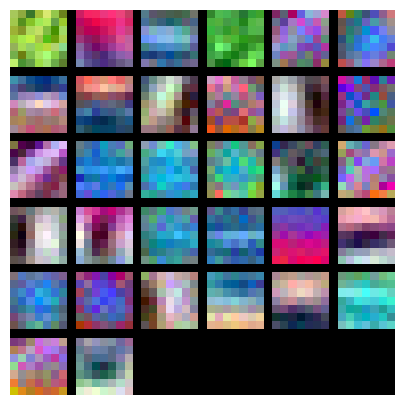

In [18]:
from cs231n.vis_utils import visualize_grid

grid = visualize_grid(model.params['W1'].transpose(0, 2, 3, 1))
plt.imshow(grid.astype('uint8'))
plt.axis('off')
plt.gcf().set_size_inches(5, 5)
plt.show()

# 空间批处理标准化
我们已经看到，批处理规范化对于训练深度全连接网络是一种非常有用的技术。批处理标准化也可以用于卷积网络，但是我们需要稍微调整一下;修改将被称为“空间批处理规范化”。

通常，批处理规范化接受shape`(N, D)`的输入，并生成shape`(N, D)`的输出，其中我们对整个minibatch维`N`进行规范化。对于来自卷积层的数据，批处理归一化需要接收shape`(N, C, H, W)`的输入，生成shape`(N, C, H, W)`的输出，其中`N`维给出的是minibatch size,`(H, W)`维给出的是feature map的空间大小。

如果feature map是使用convolutions来生成的，那么我们希望每个feature channel的统计在不同的image之间，以及在同一image内的不同位置上，是相对一致的。因此，空间批处理标准化通过计算minibatch维度`N`和空间维度`H`和`W`上的统计信息来计算每个`C`特征通道的平均值和方差。

## 空间批处理规范化:前向
在文件`cs231n/layers`中。在函数`spatial_batchnorm_forward`中实现空间批处理规范化的前向传递。检查你的实现运行以下:

**第 19 块｜检查空间 BN 的训练统计**

**工作机制与执行链。** 空间 BN 把每通道的 N、H、W 位置合并做统计。训练均值应接近 beta，尺度受 gamma 影响。

把 NCHW 特征按通道展开为 N·H·W 个观测，对每个通道独立进行 BN。检查训练模式下各通道的均值和方差，gamma、beta 的长度均为 C。



**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `spatial_batchnorm_forward` | `x=x` | (N,C,H,W) 特征图，每个通道在 N·H·W 个位置上共同估计统计量。 |
| `spatial_batchnorm_forward` | `gamma=gamma` | 可学习的逐特征缩放向量。 |
| `spatial_batchnorm_forward` | `beta=beta` | 可学习的逐特征平移向量。 |
| `spatial_batchnorm_forward` | `bn_param=bn_param` | BN 的模式、滑动统计和数值稳定配置。 |
| `x.mean` | `axis=(0, 2, 3)` | 指定沿哪一轴汇总、比较或排序，决定结果保留哪些维度。 |
| `x.std` | `axis=(0, 2, 3)` | 指定沿哪一轴汇总、比较或排序，决定结果保留哪些维度。 |
| `out.mean` | `axis=(0, 2, 3)` | 指定沿哪一轴汇总、比较或排序，决定结果保留哪些维度。 |
| `out.std` | `axis=(0, 2, 3)` | 指定沿哪一轴汇总、比较或排序，决定结果保留哪些维度。 |

**本段设置的变量与配置。**

- `mode='train'`：选择训练或推理分支。

**进入底层实现。**

- [`spatial_batchnorm_forward`](cs231n/layers.py#L377)：把 NCHW 转为 (N·H·W,C)，复用二维 BN 对每个通道归一化，再转回 NCHW。gamma/beta 长度是 C，而不是 H·W。


**形状怎么核对。**

本块显式设定：`N=2` 表示该批次的样本数；`C=3` 表示图像或特征图的通道数；`H=4` 表示图像或特征图的高度；`W=5` 表示图像或特征图的宽度。

本次已执行单元打印：`  Shape:  (2, 3, 4, 5)`。

In [19]:
np.random.seed(231)

N, C, H, W = 2, 3, 4, 5
x = 4 * np.random.randn(N, C, H, W) + 10

print('Before spatial batch normalization:')
print('  Shape: ', x.shape)
print('  Means: ', x.mean(axis=(0, 2, 3)))
print('  Stds: ', x.std(axis=(0, 2, 3)))

gamma, beta = np.ones(C), np.zeros(C)
bn_param = {'mode': 'train'}
out, _ = spatial_batchnorm_forward(x, gamma, beta, bn_param)
print('After spatial batch normalization:')
print('  Shape: ', out.shape)
print('  Means: ', out.mean(axis=(0, 2, 3)))
print('  Stds: ', out.std(axis=(0, 2, 3)))

gamma, beta = np.asarray([3, 4, 5]), np.asarray([6, 7, 8])
out, _ = spatial_batchnorm_forward(x, gamma, beta, bn_param)
print('After spatial batch normalization (nontrivial gamma, beta):')
print('  Shape: ', out.shape)
print('  Means: ', out.mean(axis=(0, 2, 3)))
print('  Stds: ', out.std(axis=(0, 2, 3)))

Before spatial batch normalization:
  Shape:  (2, 3, 4, 5)
  Means:  [9.33463814 8.90909116 9.11056338]
  Stds:  [3.61447857 3.19347686 3.5168142 ]
After spatial batch normalization:
  Shape:  (2, 3, 4, 5)
  Means:  [ 6.18949336e-16  5.99520433e-16 -1.22124533e-16]
  Stds:  [0.99999962 0.99999951 0.9999996 ]
After spatial batch normalization (nontrivial gamma, beta):
  Shape:  (2, 3, 4, 5)
  Means:  [6. 7. 8.]
  Stds:  [2.99999885 3.99999804 4.99999798]


**第 20 块｜检查空间 BN 的推理统计**

**工作机制与执行链。** 先以训练模式积累统计量再切推理，对独立输入检查输出。推理统计来自历史 batch，而不是当前图像。

先积累空间 BN 的滑动统计，再用 test 模式检查独立输入。空间位置和批次共同参与训练统计，但推理时只使用固定 running_mean/var。



**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `spatial_batchnorm_forward` | `x=x` | (N,C,H,W) 特征图，每个通道在 N·H·W 个位置上共同估计统计量。 |
| `spatial_batchnorm_forward` | `gamma=gamma` | 可学习的逐特征缩放向量。 |
| `spatial_batchnorm_forward` | `beta=beta` | 可学习的逐特征平移向量。 |
| `spatial_batchnorm_forward` | `bn_param=bn_param` | BN 的模式、滑动统计和数值稳定配置。 |
| `a_norm.mean` | `axis=(0, 2, 3)` | 指定沿哪一轴汇总、比较或排序，决定结果保留哪些维度。 |
| `a_norm.std` | `axis=(0, 2, 3)` | 指定沿哪一轴汇总、比较或排序，决定结果保留哪些维度。 |

**本段设置的变量与配置。**

- `mode='train'`：选择训练或推理分支。

**进入底层实现。**

- [`spatial_batchnorm_forward`](cs231n/layers.py#L377)：把 NCHW 转为 (N·H·W,C)，复用二维 BN 对每个通道归一化，再转回 NCHW。gamma/beta 长度是 C，而不是 H·W。


**形状怎么核对。**

本块显式设定：`N=10` 表示该批次的样本数；`C=4` 表示图像或特征图的通道数；`H=11` 表示图像或特征图的高度；`W=12` 表示图像或特征图的宽度。

由构造或 reshape 的实参可直接读出：`gamma` → `(4,)`；`beta` → `(4,)`。

In [20]:
np.random.seed(231)
N, C, H, W = 10, 4, 11, 12

bn_param = {'mode': 'train'}
gamma = np.ones(C)
beta = np.zeros(C)
for t in range(50):
  x = 2.3 * np.random.randn(N, C, H, W) + 13
  spatial_batchnorm_forward(x, gamma, beta, bn_param)
bn_param['mode'] = 'test'
x = 2.3 * np.random.randn(N, C, H, W) + 13
a_norm, _ = spatial_batchnorm_forward(x, gamma, beta, bn_param)

print('After spatial batch normalization (test-time):')
print('  means: ', a_norm.mean(axis=(0, 2, 3)))
print('  stds: ', a_norm.std(axis=(0, 2, 3)))

After spatial batch normalization (test-time):
  means:  [-0.08034406  0.07562881  0.05716371  0.04378383]
  stds:  [0.96718744 1.0299714  1.02887624 1.00585577]


## 空间批处理规范化:后向
在文件`cs231n/layers`中在函数`spatial_batchnorm_back`中实现空间批处理规范化的后向遍历。运行以下程序来检查你的实现使用数值梯度检查:

**第 21 块｜核对空间 BN 导数**

**工作机制与执行链。** 核对 dx、dgamma、dbeta；转成二维 BN 的布局和还原 NCHW 的次序必须互逆。

对空间 BN 的 x、gamma、beta 作数值检查。实现先转置并展平到二维 BN，再恢复 NCHW，反向必须严格使用相反的形状转换。

前序输入：`rel_error` 来自第 2 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |
| `eval_numerical_gradient_array` | `x=x` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=gamma` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `eval_numerical_gradient_array` | `x=beta` | 被加 h、减 h 的输入数组，扰动后必须恢复原值。 |
| `spatial_batchnorm_forward` | `x=x` | (N,C,H,W) 特征图，每个通道在 N·H·W 个位置上共同估计统计量。 |
| `spatial_batchnorm_forward` | `gamma=gamma` | 可学习的逐特征缩放向量。 |
| `spatial_batchnorm_forward` | `beta=beta` | 可学习的逐特征平移向量。 |
| `spatial_batchnorm_forward` | `bn_param=bn_param` | BN 的模式、滑动统计和数值稳定配置。 |
| `spatial_batchnorm_backward` | `dout=dout` | 后续层传回的上游梯度，形状与本层输出相同。 |
| `spatial_batchnorm_backward` | `cache=cache` | 前向留下的中间状态，反向按对应顺序读取。 |
| `rel_error` | `x=dx_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dx` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=da_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dgamma` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `rel_error` | `x=db_num` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=dbeta` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |

**本段设置的变量与配置。**

- `mode='train'`：选择训练或推理分支。

**进入底层实现。**

- [`eval_numerical_gradient_array`](cs231n/gradient_check.py#L41)：当 f 返回数组时，用初始版本 df 加权输出差分，得到链式法则对应的标量方向导数。每次扰动后恢复 x，返回与 x 同形状的数值梯度。
- [`spatial_batchnorm_forward`](cs231n/layers.py#L377)：把 NCHW 转为 (N·H·W,C)，复用二维 BN 对每个通道归一化，再转回 NCHW。gamma/beta 长度是 C，而不是 H·W。
- [`spatial_batchnorm_backward`](cs231n/layers.py#L401)：先把初始版本 NCHW 梯度转换为二维 BN 布局，执行反向，再恢复原图像布局。输出 dx 和按通道聚合的 dgamma、dbeta。


**形状怎么核对。**

本块显式设定：`N=2` 表示该批次的样本数；`C=3` 表示图像或特征图的通道数；`H=4` 表示图像或特征图的高度；`W=5` 表示图像或特征图的宽度。

由构造或 reshape 的实参可直接读出：`gamma` → `(3,)`；`beta` → `(3,)`；`dout` → `(2, 3, 4, 5)`。

**这里没有显式传入、但实际生效的默认参数。**

- `eval_numerical_gradient_array(..., h=1e-05)`：中心差分步长：太大可能跨越非光滑点，太小会放大浮点消去误差。

In [21]:
np.random.seed(231)
N, C, H, W = 2, 3, 4, 5
x = 5 * np.random.randn(N, C, H, W) + 12
gamma = np.random.randn(C)
beta = np.random.randn(C)
dout = np.random.randn(N, C, H, W)

bn_param = {'mode': 'train'}
fx = lambda x: spatial_batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: spatial_batchnorm_forward(x, gamma, beta, bn_param)[0]
fb = lambda b: spatial_batchnorm_forward(x, gamma, beta, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma, dout)
db_num = eval_numerical_gradient_array(fb, beta, dout)

_, cache = spatial_batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = spatial_batchnorm_backward(dout, cache)
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  2.786648197756335e-07
dgamma error:  7.0974817113608705e-12
dbeta error:  3.275608725278405e-12


# 额外信用描述
如果您为了获得额外的学分而实现了任何其他特性，请在这里用指向此文件或其他文件(如果适用)中的任何代码的指针清楚地描述它们。

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**工作机制与执行链。** globals() 提供当前 notebook 的命名空间。save_experiment 按约定变量名读取已经算出的标量、曲线和模型，把它们写到本题独立输出目录。这里没有前向、反向或新的参数更新；没有适用标量的题，数值检查和图像仍保存在前面的单元输出。

**第 22 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [22]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '009_ConvolutionalNetworks')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**实际修复与验证。** 重新构建当前 Python 的 Cython 扩展，快速与朴素卷积前后向一致；完整卷积模型还与独立自动求导实现对照。

**结果。** 一轮正式训练达到训练 55.8%、验证 53.2%。小样本过拟合实验与正式结果分开记录，不能混用其分母。

**方法选择。** im2col 与快速池化已是原题提供的工程路径，不把编译成功当作算法创新。更深模型及轻量实现放在下一题，保留本题可读的手写反向。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。